In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
logs = [
    # '/data/models/bin/reference_logs/swin_tiny_20260115_132240/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_20260205_233727/',
    '/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260206_130501/',
]
labels = ['swin_old', 'swin_new', 'swin_optim']

swin_old -- Train Min: (1.1039). Val Min: (1.119)
swin_new -- Train Min: (0.8901). Val Min: (0.9653)


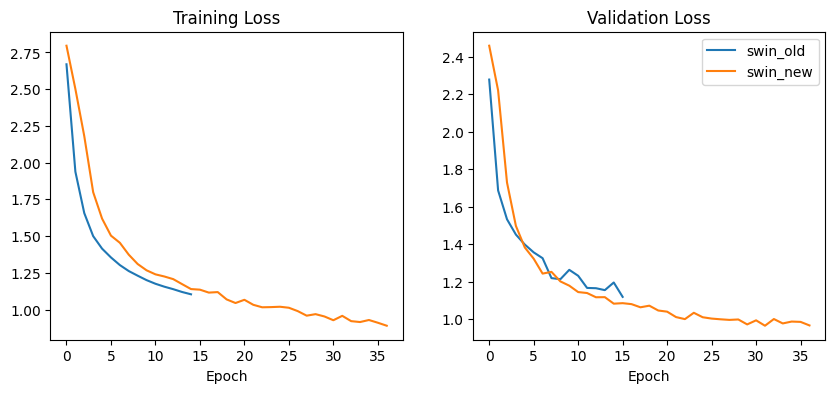

In [2]:
fig, axs = plt.subplots(1,2, figsize=(10,4))
for i, log in enumerate(logs):
    loss = np.load(log+'loss_log.pkl', allow_pickle=True)
    train = np.stack(loss['train'])
    val = np.stack(loss['val'])
    if '2026_pathway_generation' in log:
        train = train[:,2]
        val = val[:,2]
        if 'ddp' in log:
            loss_cont = np.load('/data/models/bin/2026_pathway_generation/reference_logs/swin_tiny_ddp_graph_20260207_172002_cont/loss_log.pkl', allow_pickle=True)
            train_cont = np.stack(loss_cont['train'])
            val_cont = np.stack(loss_cont['val'])
            train_cont = train_cont[:,2]
            val_cont = val_cont[:,2]            
            train = np.concat([train, train_cont])
            val = np.concat([val, val_cont])
            count = len(train)//572
            train = [np.mean(train[i*572:(i+1)*572]) for i in range(count)]
        else:
            count = len(train)//2288
            train = [np.mean(train[i*2288:(i+1)*2288]) for i in range(count)]
    print(f'{labels[i]} -- Train Min: ({round(np.min(train), 4)}). Val Min: ({round(np.min(val), 4)})')
    axs[0].plot(train, label=labels[i])
    axs[0].set_title('Training Loss')
    axs[0].set_xlabel('Epoch')
    axs[1].plot(val, label=labels[i])
    axs[1].set_title('Validation Loss')
    axs[1].set_xlabel('Epoch')
    plt.legend()
pass